### 04a. Analysis by Administration, TF-IDF and Visualizations

#### Read-In Data and Load Packages

In [1]:
import numpy as np
import pandas as pd               
import plotnine
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
import re


In [2]:
df_agency = pd.read_csv("../data/fr_rules_labels_metadata.csv")

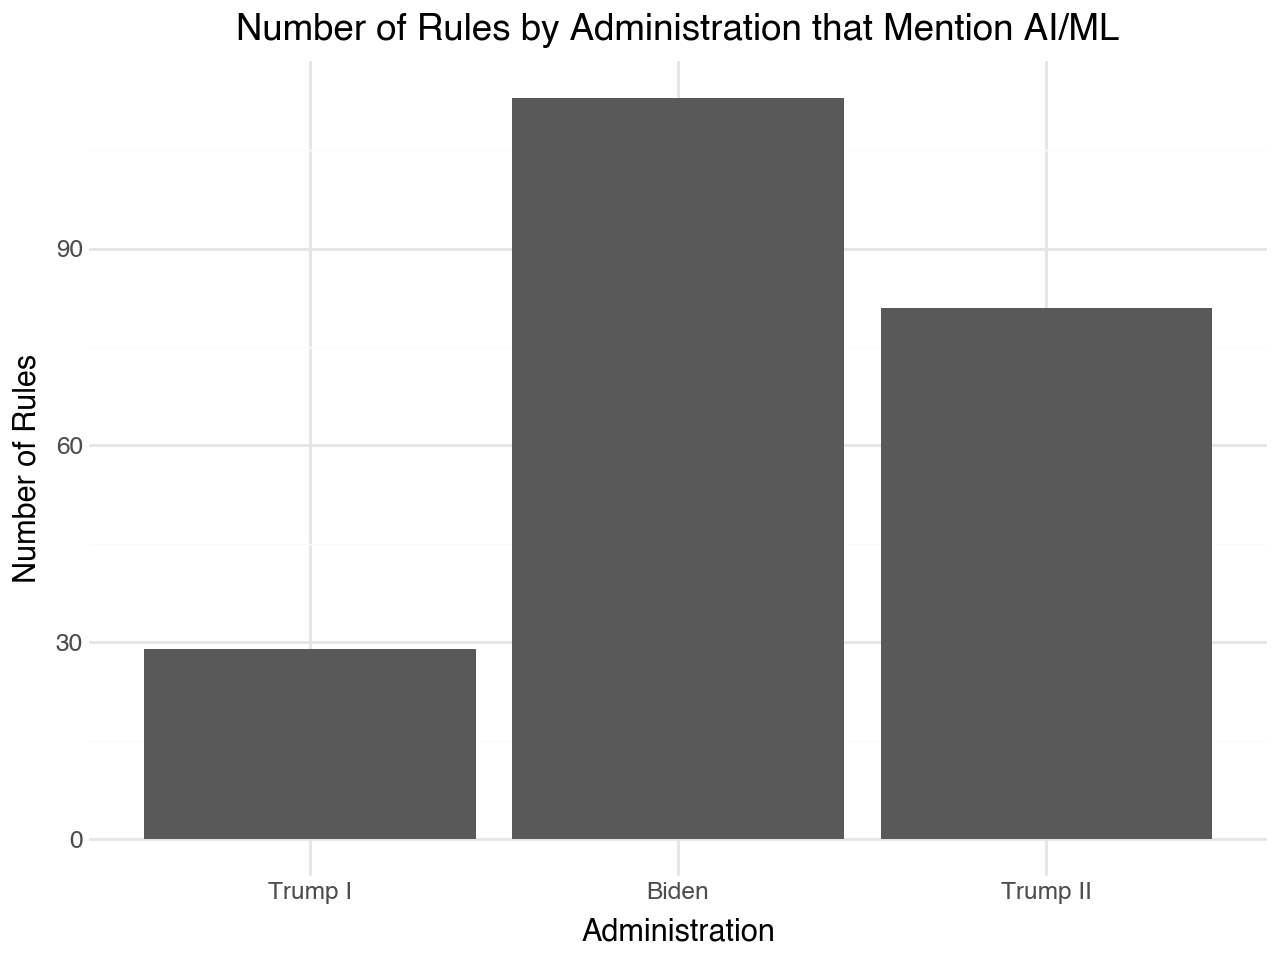

In [3]:
custom_order = ['Trump I', 'Biden', 'Trump II']
df_agency_plot = df_agency.copy()
df_agency_plot['administration'] = pd.Categorical(df_agency_plot['administration'], categories=custom_order, ordered=True)
plot1 = (plotnine.ggplot(df_agency_plot, plotnine.aes(x='administration'))
               + plotnine.geom_bar(position='dodge')
               + plotnine.labs(title='Number of Rules by Administration that Mention AI/ML',
                        x='Administration',
                        y='Number of Rules')
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1))
                + plotnine.theme_minimal())

plot1

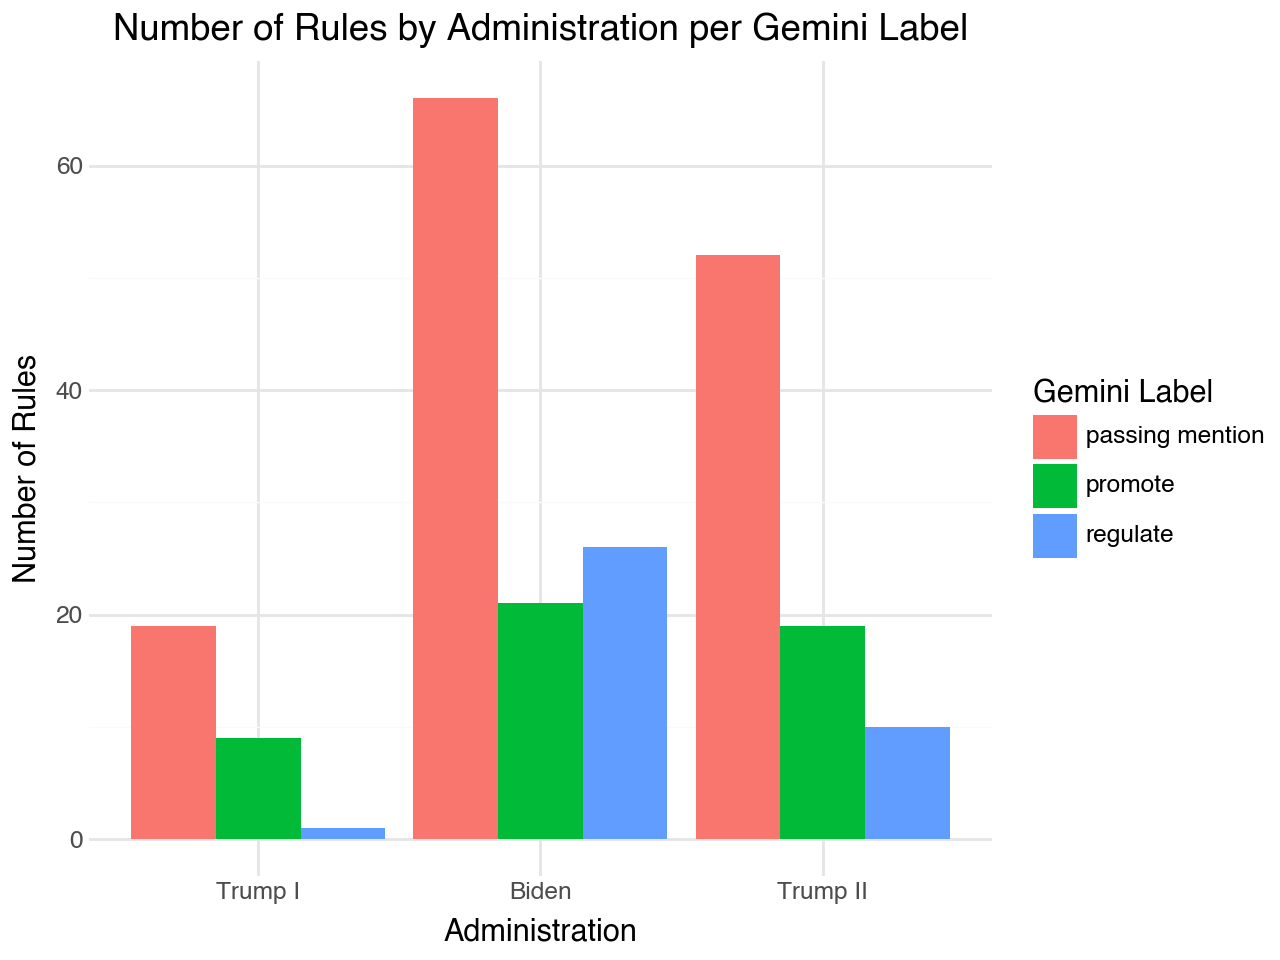

In [4]:
plot2 = (plotnine.ggplot(df_agency_plot, plotnine.aes(x='administration', fill='gemini_label'))
               + plotnine.geom_bar(position='dodge')
               + plotnine.labs(title='Number of Rules by Administration per Gemini Label',
                        x='Administration',
                        y='Number of Rules',
                        fill ='Gemini Label')
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1))
                + plotnine.theme_minimal())

plot2

In [5]:
df_agency_matched = df_agency_plot.copy()
df_agency_matched[ 'matched_artificial_intelligence' ] = df_agency_matched[ 'matched_terms' ].str.contains('artificial intelligence', case=False, na=False)
df_agency_matched[ 'matched_machine_learning' ] = df_agency_matched[ 'matched_terms' ].str.contains('machine learning', case=False, na=False)
df_agency_matched[ 'matched_automated_decision' ] = df_agency_matched[ 'matched_terms' ].str.contains('automated decision', case=False, na=False)
df_agency_matched[ 'matched_deep_learning' ] = df_agency_matched[ 'matched_terms' ].str.contains('deep learning', case=False, na=False)
df_agency_matched[ 'matched_large_language_model' ] = df_agency_matched[ 'matched_terms' ].str.contains('large language model', case=False, na=False)  

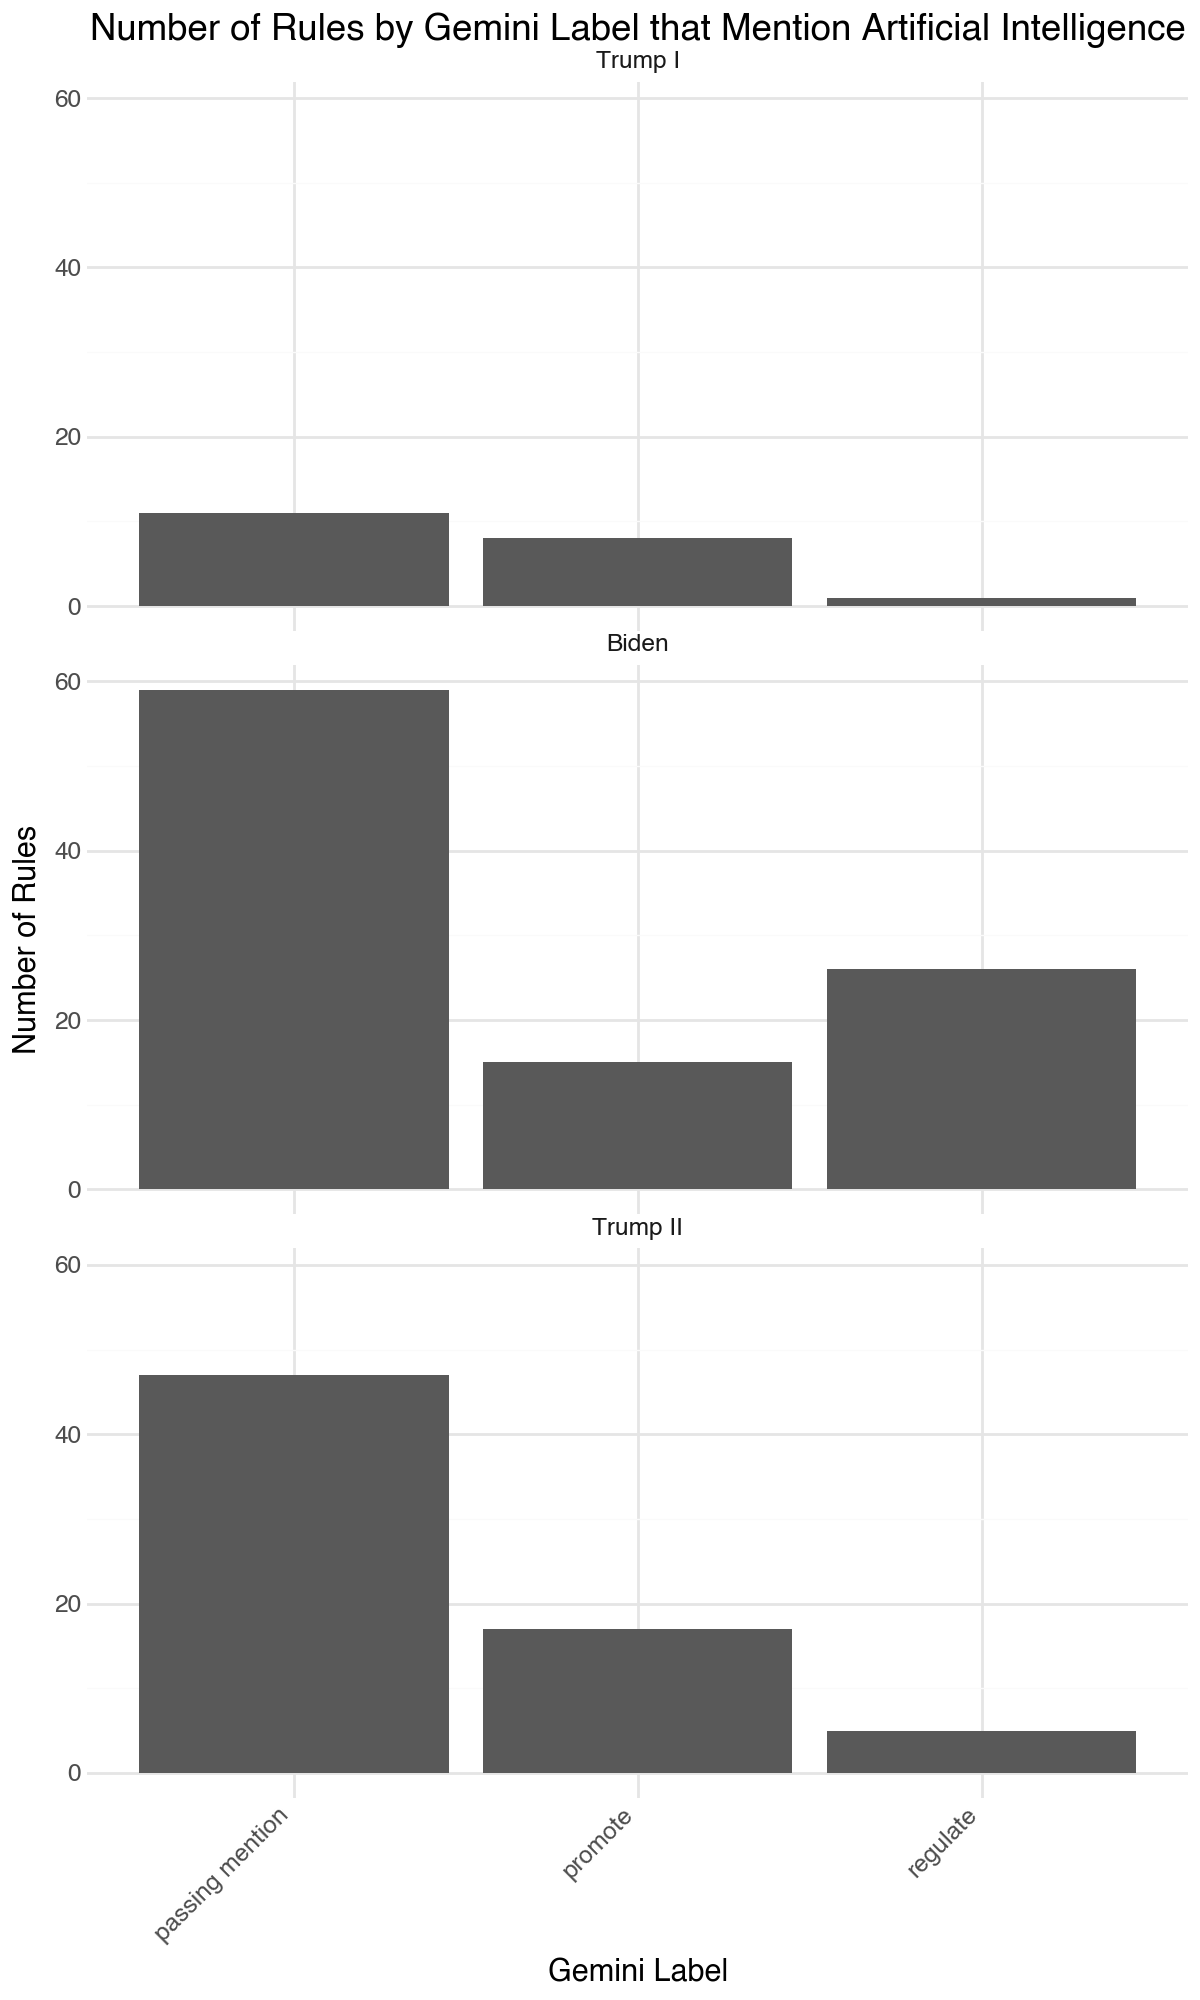

In [6]:
df_ai_true = df_agency_matched[df_agency_matched['matched_artificial_intelligence'] == True]
plot3a = (plotnine.ggplot(df_ai_true, plotnine.aes(x='gemini_label'))
               + plotnine.geom_bar()  # Single clean color instead of a legend
               + plotnine.labs(title='Number of Rules by Gemini Label that Mention Artificial Intelligence', x='Gemini Label', y='Number of Rules')
                + plotnine.theme_minimal()
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1), figure_size=(6, 10))
                + plotnine.facet_wrap('~administration', ncol=1)
)
plot3a


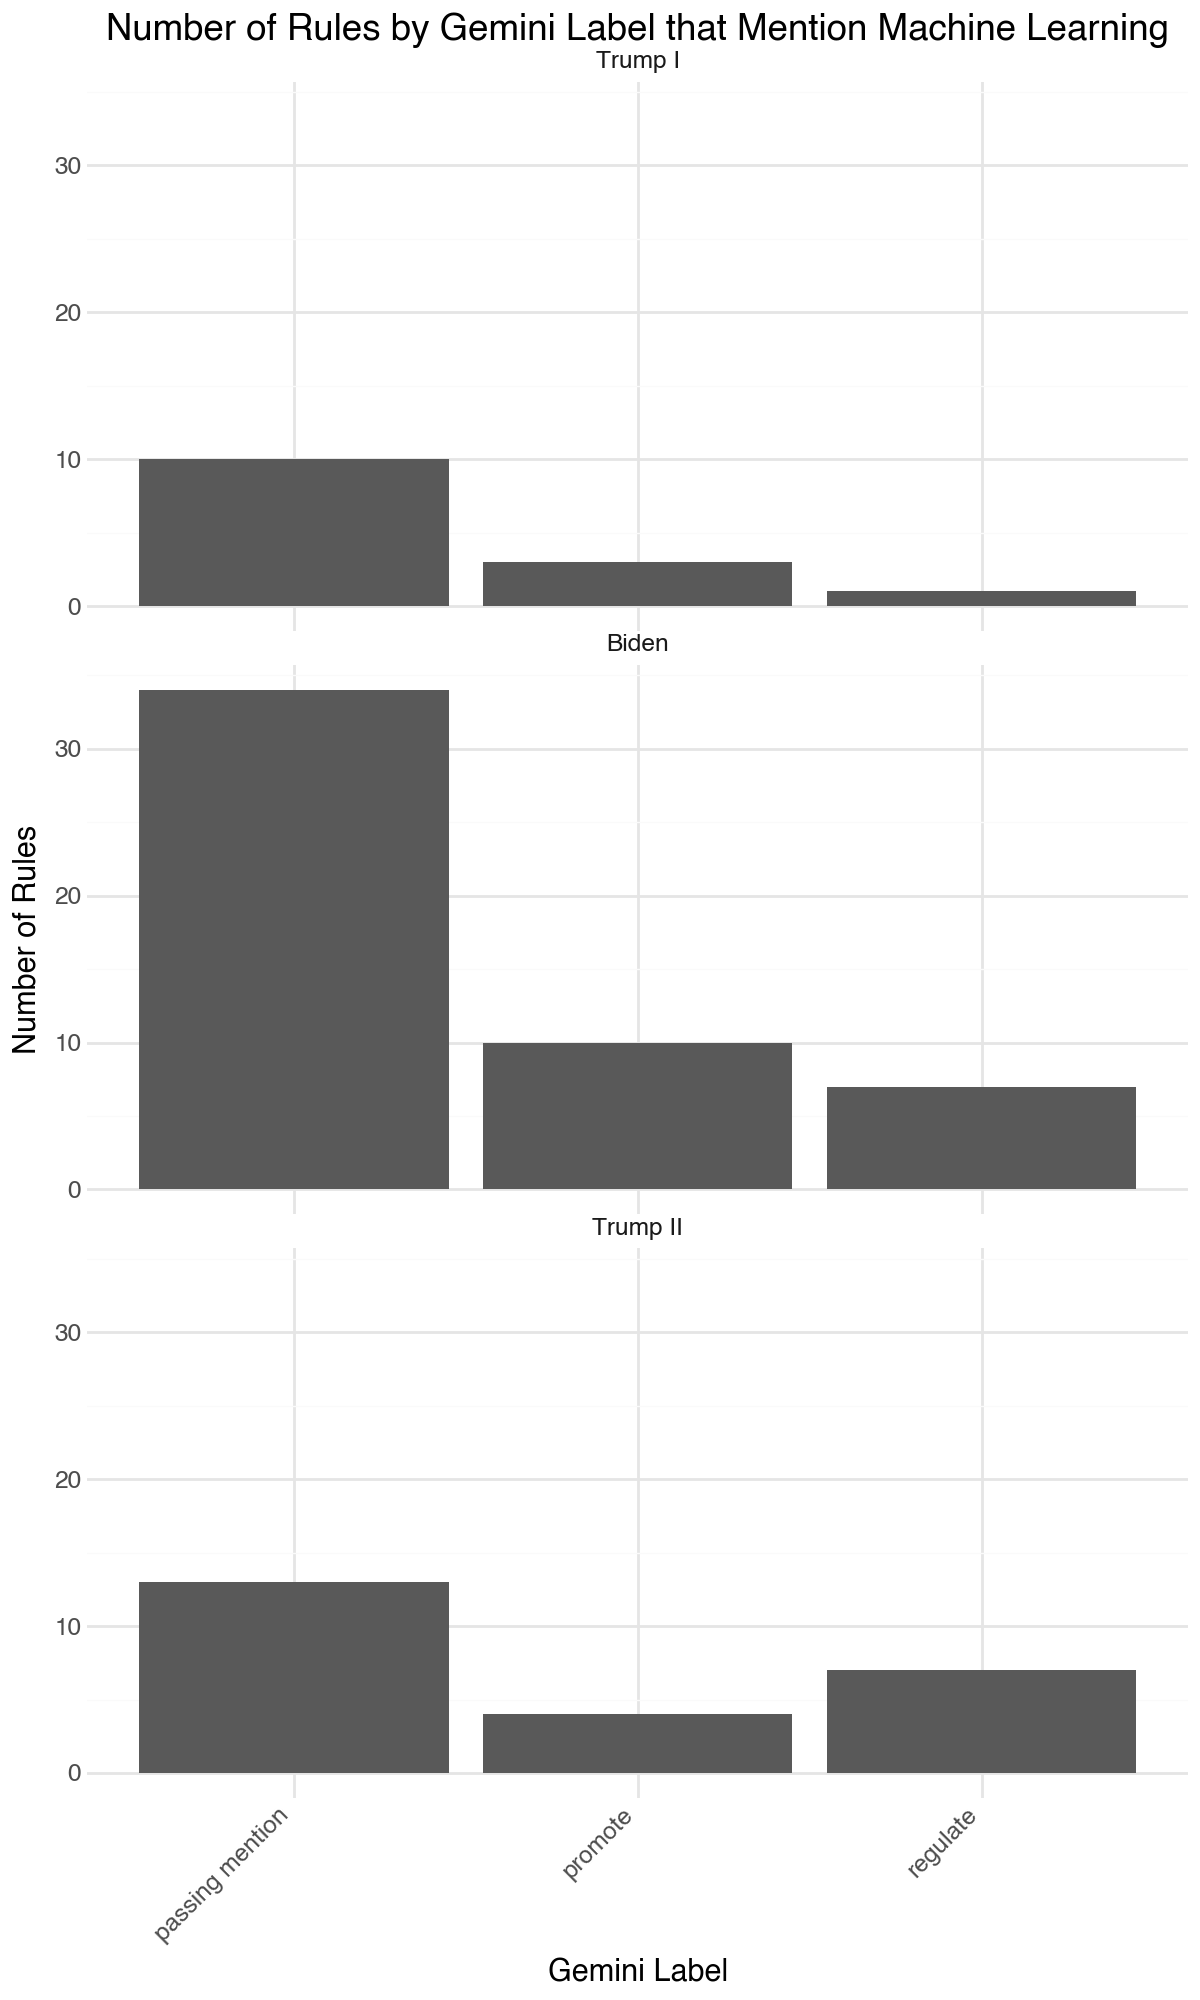

In [7]:
df_ml_true = df_agency_matched[df_agency_matched['matched_machine_learning'] == True]
plot3b = (plotnine.ggplot(df_ml_true, plotnine.aes(x='gemini_label'))
               + plotnine.geom_bar()  # Single clean color instead of a legend
               + plotnine.labs(title='Number of Rules by Gemini Label that Mention Machine Learning', x='Gemini Label', y='Number of Rules')
                + plotnine.theme_minimal()
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1), figure_size=(6, 10))
                + plotnine.facet_wrap('~administration', ncol=1)
)
plot3b


### TF-IDF BY AGENCY

In [8]:
#functions from HW4
def clean_post(text):
    """Lowercase the text, remove most punctuation, and tidy up spaces."""
    lowered = str(text).lower()
    # Replace anything that isn't a-z, 0-9, a space, an apostrophe, or a hyphen with a space.
    no_punctuation = re.sub(r"[^a-z0-9\s'-]", " ", lowered)
    # Turn runs of spaces into a single space, and trim both ends.
    return re.sub(r"\s+", " ", no_punctuation).strip()

def compare_groups(vectorizer, matrix, mask_a, mask_b, n=15):
    """Return the words whose average score differs most between two groups of rows."""
    average_a = np.asarray(matrix[mask_a].mean(axis=0)).ravel()
    average_b = np.asarray(matrix[mask_b].mean(axis=0)).ravel()
    difference = pd.DataFrame({
        "term": vectorizer.get_feature_names_out(),
        "difference": average_a - average_b,
    }).sort_values("difference", ascending=False)
    return pd.DataFrame({
        "leans_a": difference["term"].head(n).to_numpy(),
        "leans_b": difference["term"].tail(n)[::-1].to_numpy(),
    })

custom_stop_words = list(ENGLISH_STOP_WORDS | {"2019", "2020", "2021", "2022", "2023", "2024", "2025", "2026", "al", "et"})
project_vectorizer = TfidfVectorizer(stop_words=custom_stop_words, min_df=5)
df_agency["clean_text"] = df_agency["passages"].apply(clean_post)
project_matrix = project_vectorizer.fit_transform(df_agency["clean_text"])

In [9]:
trumpI = (df_agency["administration"] == "Trump I").to_numpy()
allother_trumpI = (df_agency["administration"] != "Trump I").to_numpy()
label_terms_trumpI = compare_groups(project_vectorizer, project_matrix, trumpI, allother_trumpI, n=15)
label_terms_trumpI.head(15)

,leans_a,leans_b
0,cpt,ai
1,cost,data
2,findings,agency
3,learning,public
4,applications,energy
5,disclosure,advanced
6,available,commenter
7,asserted,act
8,process,training
9,code,commission


In [10]:
biden = (df_agency["administration"] == "Biden").to_numpy()
allother_biden = (df_agency["administration"] != "Biden").to_numpy()
label_terms_biden = compare_groups(project_vectorizer, project_matrix, biden, allother_biden, n=15)
label_terms_biden.head(15)

,leans_a,leans_b
0,data,energy
1,advanced,commenters
2,research,priority
3,cybersecurity,proposed
4,systems,demand
5,credit,training
6,military,order
7,institute,analysis
8,disclosures,language
9,open,final


In [11]:
trumpII = (df_agency["administration"] == "Trump II").to_numpy()
allother_trumpII = (df_agency["administration"] != "Trump II").to_numpy()
label_terms_trumpII = compare_groups(project_vectorizer, project_matrix, trumpII, allother_trumpII, n=15)
label_terms_trumpII.head(15)

,leans_a,leans_b
0,energy,advanced
1,demand,consumer
2,training,products
3,order,data
4,ai,research
5,priority,systems
6,executive,cybersecurity
7,employment,criteria
8,electricity,learning
9,centers,section
